Tugas 2 - Perbandingan CountVectorizer vs TF-IDF pada MultinomialNB (spam.csv).

In [1]:
# Shim: notebook tidak punya __file__, kode ini warisan script .py.
import os
__file__ = os.path.abspath("mnb_count_vs_tfidf.ipynb")
print("base:", os.path.dirname(__file__))

base: C:\code\pemmes26\js09-klasifikasi\tugas-2


In [2]:
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, f1_score)
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB

HERE = Path(__file__).resolve().parent
ROOT = HERE.parent
OUT = HERE / "output"
OUT.mkdir(exist_ok=True)

path = ROOT / "data" / "spam.csv"
try:
    df = pd.read_csv(path, encoding="utf-8")
except UnicodeDecodeError:
    df = pd.read_csv(path, encoding="latin-1")
df = df.drop(columns=[c for c in df.columns if c.startswith("Unnamed")])
df = df.rename(columns={"v1": "Labels", "v2": "SMS"})[["Labels", "SMS"]].dropna()
df["Labels"] = df["Labels"].map({"spam": 1, "ham": 0})
X, y = df["SMS"].values, df["Labels"].values
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=50, stratify=y)

results = {}
for name, vec in (("CountVectorizer", CountVectorizer(stop_words="english")),
                  ("TF-IDF", TfidfVectorizer(stop_words="english"))):
    Xtr = vec.fit_transform(X_train)
    Xte = vec.transform(X_test)
    model = MultinomialNB().fit(Xtr, y_train)
    pred = model.predict(Xte)
    acc_tr = accuracy_score(y_train, model.predict(Xtr))
    acc_te = accuracy_score(y_test, pred)
    results[name] = {"fitur": Xtr.shape[1], "acc_train": acc_tr,
                     "acc_test": acc_te,
                     "f1_spam": f1_score(y_test, pred)}
    print(f"\n=== {name} (stop_words='english') ===")
    print("Jumlah fitur:", Xtr.shape[1])
    print(f"Akurasi train: {acc_tr:.4f} | test: {acc_te:.4f}")
    print("Confusion Matrix:\n", confusion_matrix(y_test, pred))
    print(classification_report(y_test, pred, target_names=["ham", "spam"],
                                digits=4))
    print("10 fitur dengan bobot tertinggi:",
          [vec.get_feature_names_out()[i] for i in
           model.feature_log_prob_[1].argsort()[-10:]][::-1])


=== CountVectorizer (stop_words='english') ===
Jumlah fitur: 7422
Akurasi train: 0.9939 | test: 0.9821
Confusion Matrix:
 [[960   6]
 [ 14 135]]
              precision    recall  f1-score   support

         ham     0.9856    0.9938    0.9897       966
        spam     0.9574    0.9060    0.9310       149

    accuracy                         0.9821      1115
   macro avg     0.9715    0.9499    0.9604      1115
weighted avg     0.9819    0.9821    0.9819      1115

10 fitur dengan bobot tertinggi: ['free', 'txt', 'ur', 'stop', 'mobile', 'text', 'claim', 'reply', 'www', 'prize']

=== TF-IDF (stop_words='english') ===
Jumlah fitur: 7422
Akurasi train: 0.9843 | test: 0.9731
Confusion Matrix:
 [[966   0]
 [ 30 119]]
              precision    recall  f1-score   support

         ham     0.9699    1.0000    0.9847       966
        spam     1.0000    0.7987    0.8881       149

    accuracy                         0.9731      1115
   macro avg     0.9849    0.8993    0.9364      1115
wei


=== Perbandingan ===
                  fitur  acc_train  acc_test  f1_spam
CountVectorizer  7422.0     0.9939    0.9821   0.9310
TF-IDF           7422.0     0.9843    0.9731   0.8881



Kesimpulan: fitur terbaik = CountVectorizer (akurasi test 0.9821)


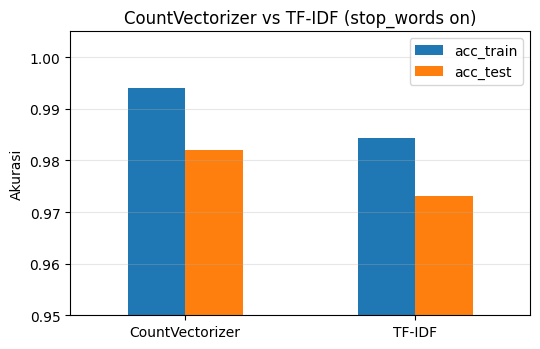

In [3]:
# Perbandingan
tbl = pd.DataFrame(results).T
tbl["acc_test"] = tbl["acc_test"].astype(float)
tbl["acc_train"] = tbl["acc_train"].astype(float)
tbl["f1_spam"] = tbl["f1_spam"].astype(float)
tbl.to_csv(OUT / "perbandingan_fitur.csv")
print("\n=== Perbandingan ===")
print(tbl.round(4).to_string())

fig, ax = plt.subplots(figsize=(5.5, 3.6))
tbl[["acc_train", "acc_test"]].plot.bar(ax=ax, rot=0)
ax.set(title="CountVectorizer vs TF-IDF (stop_words on)",
       ylabel="Akurasi", ylim=(0.95, 1.005))
ax.grid(axis="y", alpha=.3)
fig.tight_layout()
fig.savefig(OUT / "perbandingan_count_vs_tfidf.png", dpi=110)

winner = tbl["acc_test"].idxmax()
print(f"\nKesimpulan: fitur terbaik = {winner} "
      f"(akurasi test {tbl.loc[winner, 'acc_test']:.4f})")